In [1]:
import sys
path='/home/tomas/Ulmer-Berechnung/alps2qutipplus-april/alps2qutipplus-main/'

sys.path.insert(1, path) 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qutip
import scipy.linalg as linalg
import time

from alpsqutip import (build_system, list_models_in_alps_xml,
                       list_geometries_in_alps_xml, graph_from_alps_xml,
                       model_from_alps_xml,
                       restricted_maxent_toolkit as me)

from alpsqutip.operators.states.utils import safe_exp_and_normalize ## function used to safely and robustly map K-states to states

from alpsqutip.operators.states.meanfield.projections import (one_body_from_qutip_operator, 
                                                  project_operator_to_m_body, 
                                                             project_qutip_operator_to_m_body,
                                                             project_to_n_body_operator,
                                                             project_qutip_operator_as_n_body_operator)

from alpsqutip.operators import (
    ScalarOperator,
    LocalOperator,
    OneBodyOperator,
    Operator,
    ProductOperator,
    ScalarOperator,
    SumOperator,
    QutipOperator
)

from alpsqutip.scalarprod import gram_matrix, fetch_covar_scalar_product, orthogonalize_basis, orthogonalize_basis_gs
from alpsqutip.operators.states.gibbs import GibbsDensityOperator, GibbsProductDensityOperator

In [3]:
params={}

params['size']=5
params['Jx']=1.; params['Jy'] = .75*params['Jx']; params['Jz']=1.05*params['Jx']

from scipy.optimize import root, fsolve
Ffactor=np.real(max(np.roots(np.poly1d([1, 0, -(params['Jx']*params['Jy']+params['Jx']*params['Jy']+params['Jy']*params['Jz']), 
                           -2*params['Jx']*params['Jy']*params['Jz']]))))
chi_y=fsolve(lambda x,y: x*np.arcsinh(x)-np.sqrt(x**2+1)-y, 1e-1, args=(0))[0]
vLR=4*Ffactor*chi_y

In [4]:
system=build_system(geometry_name= "open chain lattice",model_name="spin", 
                    L=params['size'], J=1)

sites=[s for s in system.sites]
sx_ops=[system.site_operator("Sx", '1[' + str(a) + ']') for a in range(len(system.sites))]
sy_ops=[system.site_operator("Sy", '1[' + str(a) + ']') for a in range(len(system.sites))]
sz_ops=[system.site_operator("Sz", '1[' + str(a) + ']') for a in range(len(system.sites))]

idop = [system.site_operator('identity@1[' + str(a) + ']') for a in range(len(system.sites))]
idop = idop[0]*idop[1]*idop[2]*idop[3]*idop[4]#*idop[5]*idop[6]

Iz = sum(sz_ops)
H = 0
from itertools import combinations

Jx_coeffs = {}  # store as dict with keys (i, j)

for i, j in combinations(range(params['size']), 2):
    r = abs(i - j)
    Jx_ij = params['Jx'] / r**3
    Jy_ij = params['Jy'] / r**3
    Jz_ij = params['Jz'] / r**3

    Jx_coeffs[(i, j)] = Jx_ij  # store coefficient

    H += Jx_ij * sx_ops[i] * sx_ops[j]
    H += Jy_ij * sy_ops[i] * sy_ops[j]
    H += Jz_ij * sz_ops[i] * sz_ops[j]

loading model spin  over graph open chain lattice


In [5]:
HBB0=[idop, sz_ops[2], H]


phi0 = np.array([.0, -.75, 0.3])

K0 = me.k_state_from_phi_basis(phi0, HBB0)
sigma0 = GibbsDensityOperator(K0)
phi0[0] = np.log(sigma0.tr())
K0 = me.k_state_from_phi_basis(phi0, HBB0).simplify()
sigma0 = GibbsDensityOperator(K0)

timespan=np.linspace(.0, 700.1/vLR,400)
obs_SzA = sum(sz for sz in sz_ops)

[(sigma0.to_qutip() * op.to_qutip()).tr() for op in sz_ops] 

[-0.000586068234388306,
 -0.013925841744768994,
 0.17814363508430034,
 -0.013925841744769168,
 -0.0005860682343885419]

In [6]:
HBBfinal = [idop, sum(sz_ops)]


phif = np.array([.0, -.5])

Kf = me.k_state_from_phi_basis(phif, HBBfinal)
sigmaf = GibbsProductDensityOperator(Kf)
phi0[0] = np.log(sigma0.tr())
Kf = me.k_state_from_phi_basis(phif, HBBfinal).simplify()
sigmaf = GibbsProductDensityOperator(Kf)

obs_SzA = sum(sz for sz in sz_ops)

[(sigmaf.to_qutip() * op.to_qutip()).tr() for op in sz_ops] 

[0.1224593312018546,
 0.1224593312018546,
 0.1224593312018546,
 0.1224593312018546,
 0.12245933120185462]

In [7]:
tgt_obs=obs_SzA

In [8]:
res_exact=qutip.mesolve(H=H.to_qutip(), tlist=timespan, rho0=sigma0.to_qutip(), e_ops=[tgt_obs.to_qutip()])

In [9]:
simulations={}
simulations[1] = {
    "parms":{
    "chosen_depth": 6,
    "m0": 3,
    "eps": 1e-2,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[1]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [11]:
# phi0_proj_act_MF = []; local_bound_error_ell=[]
local_bound_error_ell = []
simulations[1]["evs"] = [(sigma0.to_qutip()* obs_SzA.to_qutip()).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                          seed_op=tgt_obs.to_qutip_operator(),
                                          deep=chosen_depth,
                                          to_qutip_operator=True)

HBB_ell_act = [op.simplify() for op in HBB_ell_act]

orth_basis_act = orthogonalize_basis(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act = me.fn_hij_tensor(generator=H.to_qutip_operator(), 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(tgt_obs.to_qutip_operator(), op.to_qutip_operator()) for op in orth_basis_act]
phi_at_timet=[phi0_proj_act]
for t in timespan[1:]:
    start=time.time()
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    phi_at_timet.append(phi_local)
    
    print(f"A. phi-local, {time.time() - start:.2f}s");   start=time.time();
    
    obs_local=me.k_state_from_phi_basis(phi=phi_local,
                                        basis=orth_basis_act) ### i put the minus in order to get a plusK
    
    stability_factor = linalg.norm(obs_local.to_qutip())
    
    print(f"B. K-local, {time.time() - start:.2f}s");   start=time.time();
        
    simulations[1]["evs"].append((sigma0*obs_local).tr()) ### the minus is here
    
    print(f"C. obs-calc, {time.time() - start:.2f}s");   start=time.time();
    
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2)
                                 / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        local_t_value = t ; start = time.time()
        
        print("a. start t=", list(timespan).index(t))
        
        start = time.time()
        
        HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                                            seed_op=obs_local.to_qutip_operator(), 
                                                            deep=chosen_depth,
                                                            to_qutip_operator=False)[1:] 
        
        HBB_ell_act = [op.simplify() for op in HBB_ell_act]
        
        end = time.time(); print(f"b. HBact constr., {end - start:.6f}s")
        
        start = time.time()
        
        HBB_ell_act= ([project_operator_to_m_body
                                              (full_operator = (op/stability_factor).as_sum_of_products().simplify(), 
                                               m_max=m0,
                                               sigma_0=sigma0).to_qutip_operator()*stability_factor
                      for op in HBB_ell_act][0:])
        
        end = time.time(); print(f"c. HBact proj, {end - start:.6f}s")
        orth_basis_act = orthogonalize_basis_gs(basis=[obs_local.to_qutip_operator()]+HBB_ell_act,
                                             sp=sp_local)  
        
        Hij_tensor_act = me.fn_hij_tensor(generator=H.to_qutip_operator(), 
                                                                basis=orth_basis_act,
                                                                sp=sp_local)
        
        end = time.time(); print(f"d. Hijact constr, {end - start:.6f}s")
        
        phi0_proj_act = np.array([np.real(sp_local(obs_local, op)) for op in orth_basis_act] ).round(10)
        new_obs_local=sum(phi0a * opa for phi0a, opa in zip(phi0_proj_act, orth_basis_act))### same here
        print("Fita: Check", linalg.norm((new_obs_local - obs_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        pass

A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.09s
A. phi-local, 0.00s
B. K-local, 0.11s
C. obs-calc, 0.13s
A. phi-local, 0.01s
B. K-local, 0.11s
C. obs-calc, 0.13s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.13s
A. phi-local, 0.01s
B. K-local, 0.10s
C. obs-calc, 0.13s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.09s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.10s
A. phi-local, 0.00s
B. K-local, 0.11s
C. obs-calc, 0.13s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.15s
A. phi-local, 0.00s
B. K-local, 0.09s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.10s
C. obs-calc, 0.12s
a. start t= 13
b. HBact constr., 0.060186s
c. HBact proj, 38.306290s
d. Hijact constr, 49.421647s
Fita: Check 2.453246642824088e-10
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.12s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.09s
A. phi-local,

B. K-local, 0.16s
C. obs-calc, 0.09s
A. phi-local, 0.00s
B. K-local, 0.20s
C. obs-calc, 0.10s
A. phi-local, 0.00s
B. K-local, 0.18s
C. obs-calc, 0.12s
A. phi-local, 0.00s
B. K-local, 0.18s
C. obs-calc, 0.07s
A. phi-local, 0.01s
B. K-local, 0.15s
C. obs-calc, 0.08s
A. phi-local, 0.00s
B. K-local, 0.19s
C. obs-calc, 0.09s
A. phi-local, 0.00s
B. K-local, 0.19s
C. obs-calc, 0.07s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.08s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.08s
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.10s
a. start t= 128
b. HBact constr., 0.071953s
c. HBact proj, 53.305638s
d. Hijact constr, 63.887155s
Fita: Check 2.632883190936949e-10
A. phi-local, 0.00s
B. K-local, 0.16s
C. obs-calc, 0.12s
A. phi-local, 0.00s
B. K-local, 0.25s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.21s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.22s
C. obs-calc, 0.11s
A. phi-local, 0.00s
B. K-local, 0.18s
C. obs-calc, 0.08s
A. phi-local, 0.00s
B. K-local, 

KeyboardInterrupt: 

In [23]:
simulations[2] = {
    "parms":{
    "chosen_depth": 9,
    "m0": 5,
    "eps": 1e-3,
    },
  "saved_cut_times_index_ell":[0],
   "no_acts_ell" : [0],
    "local_bound_error_ell":[],
    "spectral_norm_Hij_tensor_ell":[],
    "instantaneous_w_errors":[],
} 

current_simulation = simulations[2]
current_simulation_parms = current_simulation["parms"]
chosen_depth = current_simulation_parms["chosen_depth"]
eps_tol = current_simulation_parms["eps"]
m0 = current_simulation_parms["m0"]

In [24]:
# phi0_proj_act_MF = []; local_bound_error_ell=[]
local_bound_error_ell = []
simulations[2]["evs"] = [(sigma0.to_qutip()* tgt_obs.to_qutip()).tr()]

sp_local=fetch_covar_scalar_product(sigma=sigma0); local_t_value=.0

HBB_ell_act = me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                          seed_op=tgt_obs.to_qutip_operator(),
                                          deep=chosen_depth,
                                          to_qutip_operator=True)

HBB_ell_act = [op.simplify() for op in HBB_ell_act]

orth_basis_act = orthogonalize_basis_gs(basis=HBB_ell_act,
                                        sp = sp_local)

Hij_tensor_act, w_errors = me.fn_hij_tensor_with_errors(generator=H.to_qutip_operator(), 
                                                        basis=orth_basis_act,
                                                        sp=sp_local)

phi0_proj_act = [sp_local(tgt_obs.to_qutip_operator(), op) for op in orth_basis_act]
phi_at_timet = [phi0_proj_act]

for t in timespan[1:]:
    start = time.time()
    phi_local=np.real(linalg.expm(Hij_tensor_act * (t - local_t_value)) @ phi0_proj_act)  
    phi_at_timet.append(phi_local)
    
    print(f"A. phi-local, {time.time() - start:.2f}s");   start=time.time();
    
    obs_local=me.k_state_from_phi_basis(phi=phi_local,
                                        basis=orth_basis_act) ### i put the minus in order to get a plusK
    stability_factor = linalg.norm(obs_local.to_qutip())
    
    print(f"B. K-local, {time.time() - start:.2f}s");   start=time.time();
    
    simulations[2]["evs"].append((obs_local * sigma0.to_qutip_operator()).tr()) ### the minus is here
    
    print(f"C. obs-calc, {time.time() - start:.2f}s");   start=time.time();
        
    local_bound_error_ell.append(me.m_th_partial_sum(phi=phi_local, m=2)
                                 / me.m_th_partial_sum(phi=phi_local, m=0))
    
    if abs(local_bound_error_ell[-1]) >= eps_tol:
        
        local_t_value = t ; start = time.time()
        
        print("___a. start act t=", list(timespan).index(t))
        
        start = time.time()
        
        obs_proj_m0=(project_operator_to_m_body(full_operator=(obs_local/stability_factor).as_sum_of_products(),
                                         sigma_0=sigmaf, 
                                         m_max=m0)).simplify()*stability_factor
        
        local_deltaK = sp_local(obs_local-obs_proj_m0, obs_local-obs_proj_m0)
        local_deltaK = np.real(local_deltaK/sp_local(obs_local, obs_local))
        print(f"___a. bis. Delta K = ", local_deltaK*100, "%")
        
        end = time.time(); print(f"___b. obs-act-m0proj, {end - start:.2f}s")
        
        HBB_ell_act = [obs_local]+me.build_hierarchical_basis(generator=H.to_qutip_operator(),
                                                            seed_op=obs_proj_m0.to_qutip_operator(), 
                                                            deep=chosen_depth-1,
                                                            to_qutip_operator=True)
        
        HBB_ell_act = [op.simplify() for op in HBB_ell_act] 
        
        end = time.time(); print(f"___c. HBact proj, {end - start:.2f}s")
        orth_basis_act = orthogonalize_basis_gs(basis=HBB_ell_act,
                                             sp=sp_local)  
        
        start = time.time()
        
        Hij_tensor_act = me.fn_hij_tensor(generator=H.to_qutip_operator(), 
                                                                basis=orth_basis_act,
                                                                sp=sp_local)
        
        end = time.time(); print(f"___d. Hijact constr, {end - start:.2f}s")
        
        phi0_proj_act = np.array([np.real(sp_local(obs_local, op)) for op in orth_basis_act] ).round(10)
        new_obs_local=sum(phi0a * opa for phi0a, opa in zip(phi0_proj_act, orth_basis_act))### same here
        print("Fita: Check", linalg.norm((new_obs_local - obs_local).to_qutip()))
    else:
        # If error is below the threshold, retain the current basis and 
        pass

KeyboardInterrupt: 

/usr/lib/python3/dist-packages/matplotlib/cbook/__init__.py:1369: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


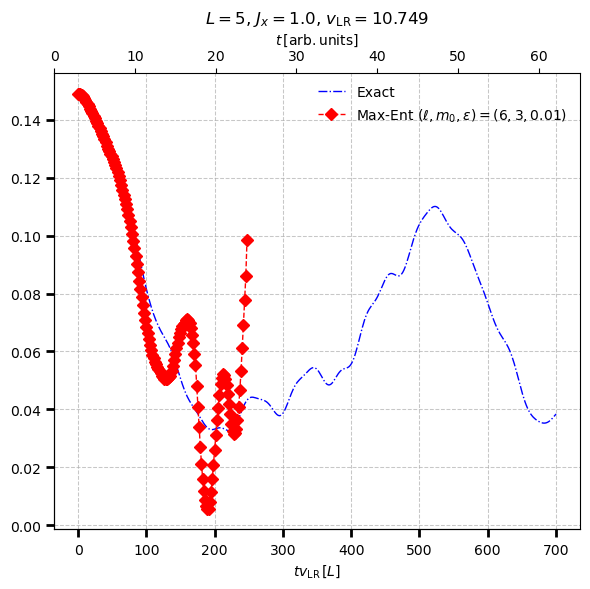

In [13]:
import matplotlib.pyplot as plt

# Création de la figure et des axes
fig, ax = plt.subplots(figsize=(6, 6))

n = 1

# Tracé de la courbe exacte
ax.plot(timespan*vLR, res_exact.expect[0] , label='Exact', color="blue", linestyle='dashdot', linewidth=1)

# Récupération des paramètres pour formater dynamiquement le label

if True: 
    l = simulations[1]["parms"]["chosen_depth"]
    m0 = simulations[1]["parms"]["m0"]
    eps = simulations[1]["parms"]["eps"]
    
    label_sim1 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'

    ax.plot(timespan[:142]*vLR, simulations[1]["evs"], 
                label=label_sim1, 
                color='red', linestyle='--', marker='D', linewidth=1)
    
if False: 
    l = simulations[2]["parms"]["chosen_depth"]
    m0 = simulations[2]["parms"]["m0"]
    eps = simulations[2]["parms"]["eps"]

    label_sim2 = fr'Max-Ent $(\ell, m_0, \epsilon) = ({l}, {m0}, {eps})$'

    ax.plot(timespan[:184]*vLR, simulations[2]["evs"], 
            label=label_sim2, 
            color='blue', linestyle='--', marker='D', linewidth=1)

# Bordures uniquement à gauche et en bas (style minimaliste)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Personnalisation des ticks
ax.tick_params(direction='out', length=6, width=2, which='major', grid_alpha=0.6)
ax.grid(True, which='major', linestyle='--', linewidth=0.75, alpha=0.7)

ax.legend(frameon=False, loc='upper right')

# Axe secondaire
ax1 = ax.twiny()
ax1.set_xlim(timespan[0], timespan[-1])

# Étiquettes des axes
ax.set_xlabel(r'$t v_{\rm LR} \, [L]$')
ax1.set_xlabel(r'$t \, [{\rm arb. units}]$')

# Titre formaté avec LaTeX
plt.title(r'$L={}$, $J_x={}$, $v_{{\rm LR}}={}$'.format(
    params['size'], 
    round(params['Jx'], 3), 
    round(vLR, 3)
))

# Ajustement final
plt.tight_layout()


In [15]:
obs_local.to_qutip()

Quantum object: dims = [[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape = (32, 32), type = oper, isherm = True
Qobj data =
[[-2.37222272e+00+0.j          0.00000000e+00+0.j
   0.00000000e+00+0.j         ...  1.13885165e-05-0.00622155j
  -3.35047524e-03-0.00857248j  0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j         -1.41288572e+00+0.j
   2.06991227e-02+0.02070051j ...  0.00000000e+00+0.j
   0.00000000e+00+0.j          3.35047524e-03-0.00857248j]
 [ 0.00000000e+00+0.j          2.06991227e-02-0.02070051j
  -1.41890346e+00+0.j         ...  0.00000000e+00+0.j
   0.00000000e+00+0.j         -1.13885165e-05-0.00622155j]
 ...
 [ 1.13885165e-05+0.00622155j  0.00000000e+00+0.j
   0.00000000e+00+0.j         ...  1.41890346e+00+0.j
  -2.06991227e-02+0.02070051j  0.00000000e+00+0.j        ]
 [-3.35047524e-03+0.00857248j  0.00000000e+00+0.j
   0.00000000e+00+0.j         ... -2.06991227e-02-0.02070051j
   1.41288572e+00+0.j          0.00000000e+00+0.j        ]
 [ 0.00000000e+00+0.j          3.3504752

In [19]:
tgt_proj=project_operator_to_m_body(full_operator = obs_local, 
                           m_max = 1,
                           sigma_0 = GibbsProductDensityOperator(idop)).to_qutip()

tgt_proj

Quantum object: dims = [[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape = (32, 32), type = oper, isherm = True
Qobj data =
[[-2.36582581  0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -1.41570956  0.         ...  0.          0.
   0.        ]
 [ 0.          0.         -1.42015325 ...  0.          0.
   0.        ]
 ...
 [ 0.          0.          0.         ...  1.42015325  0.
   0.        ]
 [ 0.          0.          0.         ...  0.          1.41570956
   0.        ]
 [ 0.          0.          0.         ...  0.          0.
   2.36582581]]

In [22]:
tgt_proj=project_operator_to_m_body(full_operator = obs_local, 
                           m_max = 1,
                           sigma_0 = sigma0).to_qutip()

tgt_proj

Quantum object: dims = [[2, 2, 2, 2, 2], [2, 2, 2, 2, 2]], shape = (32, 32), type = oper, isherm = True
Qobj data =
[[-2.36637173  0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -1.41554634  0.         ...  0.          0.
   0.        ]
 [ 0.          0.         -1.42078326 ...  0.          0.
   0.        ]
 ...
 [ 0.          0.          0.         ...  1.42065884  0.
   0.        ]
 [ 0.          0.          0.         ...  0.          1.41542193
   0.        ]
 [ 0.          0.          0.         ...  0.          0.
   2.36624732]]

In [24]:
linalg.norm(obs_local.to_qutip())

5.042793553655771

In [32]:
tgt=obs_local.as_sum_of_products()
mu = linalg.norm(tgt.to_qutip())

In [33]:
tgtproj = project_operator_to_m_body(full_operator=tgt,
                          sigma_0 = sigma0,
                          m_max = 2)

tgtproj_trick=project_operator_to_m_body(full_operator=tgt/mu,
                          sigma_0 = sigma0,
                          m_max = 2) * mu

In [34]:
linalg.norm(tgtproj.to_qutip()-tgtproj_trick.to_qutip())

4.045484099236286e-11

In [20]:
1000/vLR

93.03130333763399

In [40]:
timespan[-1]

93.04060646796776

In [39]:
timespan[-1]/params['Jx']

93.04060646796776